## 1. Hugging Face Login

#### This imports the token from Kaggle Secrets, so make sure the secret is set correctly before running the code.

In [1]:
import os
from huggingface_hub import login
from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()
HF_TOKEN = user_secrets.get_secret("HF_TOKEN")
os.environ["HF_TOKEN"] = HF_TOKEN
login(token=HF_TOKEN)

print("Hugging Face login successful.")

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Hugging Face login successful.


## 2. Check GPU

In [2]:
import torch

print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))


def get_device():
    """
      Return the computing device used in the current session.
    """
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")


DEVICE = get_device()
print("Using device:", DEVICE)
if DEVICE.type == "cuda":
    print(torch.cuda.get_device_name(0))


CUDA available: True
GPU count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4
Using device: cuda
Tesla T4


## 3. Configuration

#### this is sample configuration, you are free to modify any parameter to train the best performing model

In [3]:
import os
import random
import json
import time
import math
import zipfile
import shutil
from dataclasses import dataclass
from typing import Optional, Tuple
import torch
import torch.nn as nn
import torch.nn.functional as F

# Hugging Face dataset
HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"

# You can use any of the 4 train files or all the files for pre-training the legal model
TRAIN_SC_FILE = "Phase_1_Pretraining/Train/train_supreme_court.json"
TRAIN_HC_FILE = "Phase_1_Pretraining/Train/train_high_courts.json"
TRAIN_TRI_FILE = "Phase_1_Pretraining/Train/train_tribunals.json"
TRAIN_ACTS_FILE = "Phase_1_Pretraining/Train/train_acts.json"
TEST_FILE = "Phase_1_Pretraining/Test/test.json"

# Training configuration
TRAIN_TOKENS = 200_000_000
VAL_TOKENS = 5_000_000
TRAIN_BLOCK_SIZE = 2048
PROPORTION = {
    "acts": 0.25,
    "sc": 0.25,
    "hc": 0.30,
    "tri": 0.20
}
EPOCHS = 1
SEED = 42
random.seed(SEED)
VOCAB_SIZE = 30000;
MODEL_CONTEXT_LENGTH = 2048
N_EMBD = 768
N_LAYER = 16
N_HEAD = 8

# Generation
TARGET_GENERATION_WORDS = 128
MAX_GENERATION_TOKENS = 384
TEMPERATURE = 0.1
TOP_P = 0.95

# Kaggle output
OUTPUT_DIR = "/kaggle/working/cs781_phase1"
MODEL_OUTPUT_DIR = os.path.join(
    OUTPUT_DIR,
    "legal-gpt2-final"
)
PREDICTION_PATH = os.path.join(
    OUTPUT_DIR,
    "prediction.json"
)
SUBMISSION_ZIP = os.path.join(
    OUTPUT_DIR,
    "submission.zip"
)
LOSS_PLOT_PATH = os.path.join(
    OUTPUT_DIR,
    "training_validation_loss.png"
)
os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)
print("Configuration loaded.")

Configuration loaded.


## 4. Load Tokenizer

In [4]:
# %%writefile a1_tokenizer.py
"""Expose your Assignment-1 BPE implementation to Assignment 3.

Reuse your A-1 tokenizer code/class here. The important change is that it must be
RETRAINED on the `train_text` supplied by Assignment 3 rather than reusing a tokenizer
trained on the Assignment-1 dataset.
"""

''' Required returned interface:
      tokenizer.encode(text) -> sequence of integer ids
      tokenizer.decode(ids) -> string
      tokenizer.vocab_size OR tokenizer.get_vocab_size()'''
import re
from tqdm import tqdm
from collections import defaultdict, Counter

class ByteLevelBPE:
    def __init__(self, vocab_size=5000):
        self.vocab_size = vocab_size
        self.reserved = ["<pad>", "<unk>", "<s>", "</s>"]
        self.merges = []
        self.itos = list(self.reserved)
        self.stoi = {}
        self.ranks = {}
        self.merged_map = {}
        self._cache = {}
        # Regex pattern matching words, numbers, individual punctuation, and whitespace sequences
        pattern = r"""'s|'t|'re|'ve|'m|'ll|'d| ?[^\s\W\d_]+| ?\d+| ?[^\s\w]+|\s+(?!\S)|\s+"""
        self.pat = re.compile(pattern, re.UNICODE)
        
    def _split_text(self, text):
        """Splits text into chunks preserving whitespace, or falls back to basic regex split."""
        pattern = r"""'s|'t|'re|'ve|'m|'ll|'d| ?[^\s\W\d_]+| ?\d+| ?[^\s\w]+|\s+(?!\S)|\s+"""
        return re.findall(pattern, str(text), flags=re.UNICODE)

    def fit(self, texts, max_unique_words=200000):
        """Train a byte-level BPE tokenizer using inverted indexing for fast merging."""
        raw_counts = Counter()
        iterator = [texts] if isinstance(texts, str) else texts

        # Preserve whitespace tokens when populating initial raw_counts
        for text in tqdm(iterator, desc="Building word vocabulary"):
            for chunk in self._split_text(text):
                raw_counts[chunk] += 1

        if max_unique_words and len(raw_counts) > max_unique_words:
            most_common = raw_counts.most_common(max_unique_words)
            raw_counts = dict(most_common)

        word_freqs = {}
        pair_counts = defaultdict(int)
        pair_to_words = defaultdict(set)

        for word, count in raw_counts.items():
            encoded = word.encode("utf-8")
            byte_word = tuple(encoded[i:i+1] for i in range(len(encoded)))
            word_freqs[byte_word] = count

            for i in range(len(byte_word) - 1):
                pair = (byte_word[i], byte_word[i + 1])
                pair_counts[pair] += count
                pair_to_words[pair].add(byte_word)

        base_bytes = sorted({token for word in word_freqs for token in word})
        self.itos = list(self.reserved) + base_bytes
        self.merges = []

        target_merges = self.vocab_size - len(self.itos)

        with tqdm(total=target_merges, desc="Training BPE Merges") as pbar:
            while len(self.itos) < self.vocab_size:
                if not pair_counts:
                    break

                best_pair = max(pair_counts, key=lambda p: (pair_counts[p], p[0], p[1]))
                if pair_counts[best_pair] <= 0:
                    break

                merged_token = best_pair[0] + best_pair[1]
                self.merges.append((best_pair, merged_token))
                self.itos.append(merged_token)

                words_to_update = list(pair_to_words[best_pair])
                del pair_counts[best_pair]
                del pair_to_words[best_pair]

                p0, p1 = best_pair

                for word in words_to_update:
                    count = word_freqs.get(word, 0)
                    if count == 0:
                        continue

                    new_word = []
                    i = 0
                    n = len(word)

                    while i < n:
                        if i + 1 < n and word[i] == p0 and word[i + 1] == p1:
                            new_word.append(merged_token)
                            i += 2
                        else:
                            new_word.append(word[i])
                            i += 1

                    new_word = tuple(new_word)

                    for j in range(len(word) - 1):
                        old_p = (word[j], word[j + 1])
                        if old_p in pair_counts:
                            pair_counts[old_p] -= count
                            if pair_counts[old_p] <= 0:
                                del pair_counts[old_p]

                    for j in range(len(new_word) - 1):
                        new_p = (new_word[j], new_word[j + 1])
                        pair_counts[new_p] += count
                        pair_to_words[new_p].add(new_word)

                    del word_freqs[word]
                    word_freqs[new_word] = count

                pbar.update(1)

        self.vocab_size = len(self.itos)
        self.stoi = {token: idx for idx, token in enumerate(self.itos)}
        self.ranks = {pair: rank for rank, (pair, _) in enumerate(self.merges)}
        self.merged_map = {pair: merged for pair, merged in self.merges}
        self._cache = {}
        return self

    def encode_word(self, word):
        """Encode single word using memoization and local pair updates."""
        if word in self._cache:
            return self._cache[word]

        encoded = word.encode("utf-8")
        tokens = [encoded[i:i+1] for i in range(len(encoded))]

        if len(tokens) <= 1:
            res = [self.stoi.get(token, self.stoi["<unk>"]) for token in tokens]
            self._cache[word] = res
            return res

        while len(tokens) > 1:
            min_rank = float("inf")
            min_pair = None

            for i in range(len(tokens) - 1):
                pair = (tokens[i], tokens[i + 1])
                rank = self.ranks.get(pair, float("inf"))
                if rank < min_rank:
                    min_rank = rank
                    min_pair = pair

            if min_pair is None or min_rank == float("inf"):
                break

            merged = self.merged_map[min_pair]
            new_tokens = []
            i = 0
            n = len(tokens)
            p0, p1 = min_pair

            while i < n:
                if i + 1 < n and tokens[i] == p0 and tokens[i + 1] == p1:
                    new_tokens.append(merged)
                    i += 2
                else:
                    new_tokens.append(tokens[i])
                    i += 1
            tokens = new_tokens

        res = [self.stoi.get(token, self.stoi["<unk>"]) for token in tokens]
        self._cache[word] = res
        return res

    def encode(self, text):
        """Encode a sentence while preserving original spaces and newlines."""
        ids = [self.stoi["<s>"]]
        for chunk in self._split_text(text):
            ids.extend(self.encode_word(chunk))
        ids.append(self.stoi["</s>"])
        return ids

    def decode(self, ids):
        """Decode BPE token IDs back into text seamlessly."""
        byte_list = []
        for idx in ids:
            if 0 <= idx < len(self.itos):
                tok = self.itos[idx]
            else:
                tok = "<unk>"
            if tok not in self.reserved and isinstance(tok, bytes):
                byte_list.append(tok)
        try:
            return b"".join(byte_list).decode("utf-8", errors="ignore")
        except Exception:
            return ""

    def get_vocab_size(self):
        return self.vocab_size

def train_tokenizer(train_text: str, vocab_size: int):
    """Train A-1 BPE tokenizer on `train_text` and return the trained tokenizer."""
    tokenizer = ByteLevelBPE(vocab_size)
    tokenizer.fit(train_text)
    return tokenizer

## 5. Download Training Data From Hugging Face

In [5]:
from huggingface_hub import hf_hub_download

train_sc_file_path = hf_hub_download(
    repo_id=HF_DATASET_REPO,
    filename=TRAIN_SC_FILE,
    repo_type="dataset",
    token=HF_TOKEN
)
train_hc_file_path = hf_hub_download(
    repo_id=HF_DATASET_REPO,
    filename=TRAIN_HC_FILE,
    repo_type="dataset",
    token=HF_TOKEN
)
train_tri_file_path = hf_hub_download(
    repo_id=HF_DATASET_REPO,
    filename=TRAIN_TRI_FILE,
    repo_type="dataset",
    token=HF_TOKEN
)
train_acts_file_path = hf_hub_download(
    repo_id=HF_DATASET_REPO,
    filename=TRAIN_ACTS_FILE,
    repo_type="dataset",
    token=HF_TOKEN
)

print("Training file:")
print(train_sc_file_path)



Phase_1_Pretraining/Train/train_supreme_(…):   0%|          | 0.00/1.32G [00:00<?, ?B/s]

Phase_1_Pretraining/Train/train_high_cou(…):   0%|          | 0.00/10.7G [00:00<?, ?B/s]

Phase_1_Pretraining/Train/train_tribunal(…):   0%|          | 0.00/6.48G [00:00<?, ?B/s]

Phase_1_Pretraining/Train/train_acts.jso(…):   0%|          | 0.00/729M [00:00<?, ?B/s]

Training file:
/root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Train/train_supreme_court.json


In [6]:
import re, unicodedata
from collections import Counter

def clean_court_text(text, ascii_only=True, tables="flatten"):
    """Clean one judgment text. tables: 'flatten' | 'drop' | 'keep'.
    Dates, case numbers, court/judge names are never reformatted (integrity-checked)."""
    ROW = "\x01"
    SEP = re.compile(r"\s{3,}|\|")
    BORDER = re.compile(r"^[\s|+\-_=:.]{3,}$")
    PARA = re.compile(r"^(?:\(?\d{1,3}(?:\.\d+)*[.)]|\d{1,3}\.\d+|\(?[ivxlc]{1,5}\)|\(?[a-zA-Z]\)|-)\s+\S")
    MON = r"(?:Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Sept|Oct|Nov|Dec)[a-z]*"
    ENT = [re.compile(p, re.I) for p in (
        r"\b\d{1,2}\s*[./-]\s*\d{1,2}\s*[./-]\s*\d{2,4}\b",
        rf"\b\d{{1,2}}(?:st|nd|rd|th)?\s+{MON}\.?,?\s+\d{{4}}\b",
        rf"\b{MON}\.?\s+\d{{1,2}}(?:st|nd|rd|th)?,?\s+\d{{4}}\b",
        r"\b\d{1,7}\s*(?:of|/)\s*(?:19|20)\d{2}\b", r"\b(?:Supreme|High)\s+Court\b")]
    NOISE = [re.compile(p, re.I | re.M) for p in (
        r"indian\s*kanoon\s*-?\s*https?://\S+", r"https?://\S+", r"</?[a-z][^>]{0,100}>",
        r"\bdigitally\s+signed\s+by\b[^\n]*", r"\bsignature\s+not\s+verified\b[^\n]*",
        r"^\s*page\s+\d+\s*(?:of|/)\s*\d+\s*$")]
    DOTS = [(r"(?:\.[ \t]){3,}\.?", " ... "), (r"\.{4,}", " ... "), (r"(?<=\w)\.\.(?=\s|$)", "."),
            (r"([,;:!?])\1+", r"\1"), (r"[_=~*#]{3,}|-{3,}", " "), (r"[ \t]+([,;])(?=\s)", r"\1")]
    typo = {"\u2018": "'", "\u2019": "'", "\u201a": "'", "\u201b": "'", "\u2032": "'", "\u00b4": "'", "`": "'",
            "\u201c": '"', "\u201d": '"', "\u201e": '"', "\u201f": '"', "\u2033": '"', "\u00ab": '"', "\u00bb": '"',
            "\u2013": "-", "\u2014": "-", "\u2015": "-", "\u2010": "-", "\u2011": "-", "\u2012": "-", "\u2212": "-",
            "\u2026": "...", "\u2022": "- ", "\u25cf": "- ", "\u25aa": "- ", "\u25a0": "- ", "\u00b7": "- ",
            "\u20b9": "Rs.", "\u00a9": "(c)", "\u00ae": "", "\u2122": "", "\u00d7": "x", "\u00f7": "/",
            "\u2044": "/", "\u00a0": " ", "\u202f": " ", "\u205f": " ", "\u3000": " ", "\u2028": "\n", "\u2029": "\n\n"}
    typo.update({chr(c): " " for c in range(0x2000, 0x200b)})
    typo.update({chr(c): ("|" if chr(c) in "\u2502\u2503\u2551\u254e\u254f\u2506\u2507\u250a\u250b" else "-")
                 for c in range(0x2500, 0x2580)})
    typo = str.maketrans(typo)
    moji = re.compile(r"(?:[\u00c2-\u00f4][\u0080-\u00bf\u20ac\u201a\u0192\u201e\u2026\u2020\u2021\u02c6\u2030\u0160"
                      r"\u2039\u0152\u017d\u2018\u2019\u201c\u201d\u2022\u2013\u2014\u02dc\u2122\u0161\u203a\u0153"
                      r"\u017e\u0178]+)+")
    ctrl = re.compile(r"[\u200b-\u200f\u202a-\u202e\u2060\ufeff\u00ad\ufffd\ue000-\uf8ff\x00-\x08\x0b\x0e-\x1f\x7f]|\(cid:\d+\)")

    def fix_moji(s):
        def f(m):
            try:
                b = bytearray()
                for ch in m.group(0):
                    try: b += ch.encode("cp1252")
                    except UnicodeEncodeError:
                        if "\u0080" <= ch <= "\u009f": b.append(ord(ch))
                        else: raise
                return bytes(b).decode("utf-8")
            except (UnicodeEncodeError, UnicodeDecodeError):
                return m.group(0)
        return moji.sub(f, s)

    def ws(s):
        return re.sub(r"\n{3,}", "\n\n", re.sub(r" ?\n ?", "\n", re.sub(r"[ \t]+", " ", s))).strip()

    def entities(s):
        return {re.sub(r"\s+", "", m.group(0)).lower() for rx in ENT for m in rx.finditer(s)}

    def denoise(s):
        for rx in NOISE: s = rx.sub(" ", s)
        return s

    def heading(t):
        t = t.strip()
        return (t.startswith(ROW) or bool(re.fullmatch(r"(?i)(versus|vs?\.?|v/s)", t))
                or (len(t.split()) <= 14 and "..." in t and re.search(r"(?i)(petitioner|respondent|appellant|applicant|defendant|plaintiff)s?\W*$", t) is not None)
                or (len(t) >= 3 and t.isupper() and len(t.split()) <= 10))

    def run(src, conservative):
        s = fix_moji(src).replace("\x0c", "\n").replace("\t", "   ").replace("\r\n", "\n").replace("\r", "\n")
        s = ctrl.sub("", s).translate(typo)
        s = (unicodedata.normalize("NFKD", s).encode("ascii", "ignore").decode() if ascii_only
             else unicodedata.normalize("NFKC", s))
        base = entities(denoise(s))
        if not conservative:
            L = denoise(s).split("\n")
            # one-cell-per-line tables
            tiny = lambda l: (0 < len(l.strip()) <= 25 and re.search(r"[A-Za-z0-9]", l) and not re.search(r"[.:;?!]$", l.strip())
                              and not PARA.match(l.strip()) and not SEP.search(l.strip()))
            o, i = [], 0
            while i < len(L):
                j = i
                while tiny(L[i]) and j < len(L) and tiny(L[j]): j += 1
                if j - i >= 8:
                    if tables == "flatten": o.append(ROW + "; ".join(x.strip() for x in L[i:j]))
                    i = j
                else:
                    o.append(L[i]); i += 1
            L = o
            # row/column tables
            if tables != "keep":
                isrow = lambda l: bool(l.strip()) and bool(SEP.search(l.strip()))
                isb = lambda l: bool(BORDER.match(l.strip() or "x"))
                o, i = [], 0
                while i < len(L):
                    if isrow(L[i]) or isb(L[i]):
                        j = i
                        while j < len(L) and (isrow(L[j]) or isb(L[j])): j += 1
                        rows = [l for l in L[i:j] if not isb(l)]
                        if len(rows) >= 3 or any(len(SEP.findall(r.strip())) >= 2 for r in rows) or len(rows) < j - i:
                            if tables == "flatten":
                                o += [ROW + "; ".join(c.strip() for c in SEP.split(r.strip()) if c.strip()) for r in rows]
                            i = j; continue
                    o.append(L[i]); i += 1
                L = o
            # page numbers / symbol-only lines
            L = [l for l in L if not (l.strip() and (re.fullmatch(r"[-\[(]?\s*\d{1,4}\s*[-\])]?", l.strip())
                                                       or not re.search(r"[A-Za-z0-9]", l.strip().replace(ROW, ""))))]
            # repeated headers/footers (keep first copy)
            key = lambda l: (lambda t: re.sub(r"\d+", "#", t) if re.search(r"\bpage\b", t) else t)(re.sub(r"\s+", " ", l.strip().lower()))
            cnt = Counter(key(l) for l in L if 20 <= len(l.strip()) <= 120 and not PARA.match(l.strip()))
            seen, o = set(), []
            for l in L:
                k = key(l)
                if cnt.get(k, 0) >= 3:
                    if k in seen: continue
                    seen.add(k)
                o.append(l)
            s = re.sub(r"(?<=[a-z])-\n\s*(?=[a-z])", "", "\n".join(o))
            # unwrap hard line breaks
            res, cur = [], ""
            for l in s.split("\n"):
                t = l.strip()
                if not t:
                    if cur: res.append(cur); cur = ""
                    res.append(""); continue
                if cur and not PARA.match(t) and not heading(t) and not heading(cur): cur += " " + t
                else:
                    if cur: res.append(cur)
                    cur = t
            if cur: res.append(cur)
            s = "\n".join(res)
        for p, r in DOTS: s = re.sub(p, r, s)
        s = ws(s.replace(ROW, ""))
        if entities(s) != base:                      # safety net: never alter dates / case numbers / courts
            return run(src, True) if not conservative else ws(fix_moji(src))
        return s

    return run(text, False) if isinstance(text, str) else text

In [7]:
%pip install ijson

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 149.8/149.8 kB 5.3 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [8]:
from tqdm import tqdm
import ijson

MIN_CHARS = 200            # lower this if your acts/tribunal docs are short
MAX_DOCS_PER_SOURCE = 100_000

if not (os.path.exists("./cs781_phase1/tokenizer.pkl")
        and os.path.exists("./cs781_phase1/train_tokens.pt")
        and os.path.exists("./cs781_phase1/val_tokens.pt")):
    random.seed(SEED)
    train_text = []

    for path in [train_acts_file_path, train_sc_file_path, train_hc_file_path, train_tri_file_path]:
        kept = dropped = 0
        with open(path, "r", encoding="utf-8") as f:
            for data in tqdm(ijson.items(f, "item")):
                text = data.get("text")
                if not isinstance(text, str):
                    dropped += 1
                    continue
                cleaned = clean_court_text(text)
                if len(cleaned) < MIN_CHARS:        # replaces the old `is None` check
                    dropped += 1
                    continue
                train_text.append(cleaned)
                kept += 1
                if kept >= MAX_DOCS_PER_SOURCE:
                    break
        print(f"dropped {dropped:,}")

In [9]:
# # 
# %rm "/kaggle/working/cs781_phase1/val_tokens.pt"

In [10]:
import pickle
if not os.path.exists(OUTPUT_DIR+"/tokenizer.pkl"):
    tokenizer = train_tokenizer(train_text, VOCAB_SIZE)
    with open(OUTPUT_DIR+"/tokenizer.pkl", "wb") as f:
        pickle.dump(tokenizer, f)
else:
    with open(OUTPUT_DIR+"/tokenizer.pkl", "rb") as f:
        tokenizer = pickle.load(f)

## 6. Create Train and Validation Tokens Set

In [11]:
if not (os.path.exists(OUTPUT_DIR+"/tokenizer.pkl") and os.path.exists(OUTPUT_DIR+"/train_tokens.pt") and os.path.exists(OUTPUT_DIR+"/val_tokens.pt")):
    train_tokens = []
    val_tokens = []

    random.seed(SEED)
    sources = list(PROPORTION.keys())
    proportions = list(PROPORTION.values())
    
    target_train_per_source = [int(TRAIN_TOKENS * p) for p in proportions]
    target_val_per_source = [int(VAL_TOKENS * p) for p in proportions]
    
    for idx, (path, name) in enumerate(zip([train_acts_file_path, train_sc_file_path, train_hc_file_path, train_tri_file_path], sources)):
        source_train_collected = 0
        source_val_collected = 0
        
        target_train = target_train_per_source[idx]
        target_val = target_val_per_source[idx]
    
        print(f"Processing source: {name} (Target Train: {target_train:,}, Target"
              f" Val: {target_val:,})"
        )
        with open(path,"r", encoding="utf-8") as f:
            records = ijson.items(f, 'item')
            for data in tqdm(records):
                text = data["text"]
                if not isinstance(text, str):
                    continue
                tokens = tokenizer.encode(text)
            
                if random.random() < 0.05:
                    if source_val_collected < target_val:
                       needed = target_val - source_val_collected
                       chunk = tokens[:needed]
                       val_tokens.extend(chunk)
                       source_val_collected += len(chunk)
                else:
                    if source_train_collected < target_train:
                       needed = target_train - source_train_collected
                       chunk = tokens[:needed]
                       train_tokens.extend(chunk)
                       source_train_collected += len(chunk)
                if (
                    source_train_collected >= target_train
                    and source_val_collected >= target_val
                ):
                  break

    # Save tokens as PyTorch tensors (.pt)
    print("Saving generated tokens...")
    torch.save(train_tokens, os.path.join(OUTPUT_DIR, "train_tokens.pt"))
    torch.save(val_tokens, os.path.join(OUTPUT_DIR, "val_tokens.pt"))
    print(
      f"Finished! Total Train Tokens: {len(train_tokens):,}, Total Val"
      f" Tokens: {len(val_tokens):,}"
    )
else:
    train_tokens = torch.load(os.path.join(OUTPUT_DIR, "train_tokens.pt"), map_location="cpu")
    val_tokens = torch.load(os.path.join(OUTPUT_DIR, "val_tokens.pt"), map_location="cpu")
    print("Tokenizer and token files already exist. Skipping tokenization.")

Tokenizer and token files already exist. Skipping tokenization.


## 7. Create Token Blocks

In [12]:
def get_batch(data, batch_size, block_size):
    """Random windows from the WHOLE token stream -> every batch mixes acts / HC / SC / tribunals."""
    ix = torch.randint(0, len(data) - block_size - 1, (batch_size,)).tolist()
    x = torch.stack([data[i:i + block_size] for i in ix]).long()
    y = torch.stack([data[i + 1:i + 1 + block_size] for i in ix]).long()
    return x, y

print("Train sequences available:", (len(train_tokens) - 1) // TRAIN_BLOCK_SIZE)
print("Val sequences available:  ", (len(val_tokens) - 1) // TRAIN_BLOCK_SIZE)

Train sequences available: 97656
Val sequences available:   2441


## 8. Create Datasets

In [13]:
# from datasets import Dataset

# train_dataset = Dataset.from_dict({"input_ids": train_blocks})
# val_dataset = Dataset.from_dict({"input_ids": val_blocks})

# print(train_dataset)
# print(val_dataset)

## 9. Define The Model

## LMConfig

In [14]:
@dataclass
class LMConfig:
    # ---- general ----
    vocab_size: int = VOCAB_SIZE
    max_seq_len: int = MODEL_CONTEXT_LENGTH
    d_model: int = N_EMBD
    n_layers: int = N_LAYER
    dropout: float = 0.0
    bias: bool = False
    tie_embeddings: bool = True
    norm_type: str = "rmsnorm"          # "rmsnorm" | "layernorm"
    norm_eps: float = 1e-6

    # ---- positional ----
    pos_emb_type: str = "rope"          # "rope" | "sinusoidal"
    rope_theta: float = 10000.0

    # ---- attention ----
    attn_type: str = "gqa"              # "gqa" | "mla"
    n_heads: int = N_HEAD
    # GQA (n_kv_heads == n_heads -> MHA, 1 -> MQA)
    n_kv_heads: int = 2
    head_dim: Optional[int] = None      # defaults to d_model // n_heads
    # MLA
    q_lora_rank: Optional[int] = 256    # None -> no query compression
    kv_lora_rank: int = 128
    qk_nope_head_dim: int = 48
    qk_rope_head_dim: int = 16
    v_head_dim: int = 64

    # ---- feed-forward ----
    ffn_type: str = "dense"             # "dense" | "moe"
    d_ff: int = 2048
    # MoE
    n_experts: int = 8
    top_k: int = 2
    n_shared_experts: int = 1
    expert_d_ff: int = 512
    aux_loss_coef: float = 0.01
    first_k_dense_layers: int = 0       # first k layers stay dense
    moe_layer_freq: int = 1             # after that, every n-th layer is MoE

    def __post_init__(self):
        assert self.norm_type in ("rmsnorm", "layernorm")
        assert self.pos_emb_type in ("rope", "sinusoidal")
        assert self.attn_type in ("gqa", "mla")
        assert self.ffn_type in ("dense", "moe")

        if self.pos_emb_type == "sinusoidal":
            assert self.d_model % 2 == 0, "sinusoidal needs even d_model"

        if self.attn_type == "gqa":
            if self.head_dim is None:
                assert self.d_model % self.n_heads == 0, "d_model must be divisible by n_heads"
                self.head_dim = self.d_model // self.n_heads
            assert self.n_heads % self.n_kv_heads == 0, "n_heads must be divisible by n_kv_heads"
            if self.pos_emb_type == "rope":
                assert self.head_dim % 2 == 0, "RoPE needs even head_dim"
        else:
            if self.pos_emb_type == "rope":
                assert self.qk_rope_head_dim % 2 == 0 and self.qk_rope_head_dim > 0

        if self.ffn_type == "moe":
            assert 1 <= self.top_k <= self.n_experts

    @property
    def rope_dim(self) -> int:
        return self.qk_rope_head_dim if self.attn_type == "mla" else self.head_dim

    def is_moe_layer(self, layer_idx: int) -> bool:
        if self.ffn_type != "moe" or layer_idx < self.first_k_dense_layers:
            return False
        return (layer_idx - self.first_k_dense_layers) % self.moe_layer_freq == 0

## Normalization layers

In [15]:
class RMSNorm(nn.Module):
    def __init__(self, dim: int, eps: float = 1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))

    def forward(self, x):
        dtype = x.dtype
        x = x.float()
        x = x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps)
        return (x * self.weight.float()).to(dtype)


def make_norm(cfg: LMConfig, dim: int) -> nn.Module:
    if cfg.norm_type == "rmsnorm":
        return RMSNorm(dim, cfg.norm_eps)
    return nn.LayerNorm(dim, eps=cfg.norm_eps)

## Positional embeddings (RoPE and sinusoidal)

In [16]:
class RoPE(nn.Module):
    """Rotary embedding. Rotates q and k of shape (B, H, T, dim)."""

    def __init__(self, dim: int, max_seq_len: int, theta: float = 10000.0):
        super().__init__()
        inv_freq = 1.0 / (theta ** (torch.arange(0, dim, 2).float() / dim))
        t = torch.arange(max_seq_len).float()
        freqs = torch.outer(t, inv_freq)               # (L, dim/2)
        emb = torch.cat([freqs, freqs], dim=-1)        # (L, dim)
        self.register_buffer("cos", emb.cos(), persistent=False)
        self.register_buffer("sin", emb.sin(), persistent=False)

    @staticmethod
    def _rotate_half(x):
        x1, x2 = x.chunk(2, dim=-1)
        return torch.cat([-x2, x1], dim=-1)

    def rotate(self, x, positions):
        cos, sin = self.cos[positions], self.sin[positions]
        if cos.dim() == 2:                              # positions: (T,)
            cos, sin = cos[None, None], sin[None, None]
        else:                                           # positions: (B, T)
            cos, sin = cos[:, None], sin[:, None]
        cos, sin = cos.to(x.dtype), sin.to(x.dtype)
        return x * cos + self._rotate_half(x) * sin

    def forward(self, q, k, positions):
        return self.rotate(q, positions), self.rotate(k, positions)


class SinusoidalPositionalEmbedding(nn.Module):
    """Fixed sin/cos table, added to token embeddings once at model level."""

    def __init__(self, d_model: int, max_seq_len: int):
        super().__init__()
        pos = torch.arange(max_seq_len).float().unsqueeze(1)
        div = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe = torch.zeros(max_seq_len, d_model)
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe, persistent=False)

    def forward(self, x, offset: int = 0):
        T = x.size(1)
        return x + self.pe[offset:offset + T].to(x.dtype)

## Attention helper and GQA

In [28]:
def causal_sdpa(q, k, v, dropout_p: float = 0.0, training: bool = False):
    """Causal attention that also works when k/v are longer than q (KV cache)."""
    Tq, Tk = q.size(2), k.size(2)
    p = dropout_p if training else 0.0
    if Tq == Tk:
        return F.scaled_dot_product_attention(q, k, v, dropout_p=p, is_causal=True)
    if Tq == 1:
        return F.scaled_dot_product_attention(q, k, v, dropout_p=p)
    mask = torch.ones(Tq, Tk, dtype=torch.bool, device=q.device).tril(diagonal=Tk - Tq)
    return F.scaled_dot_product_attention(q, k, v, attn_mask=mask, dropout_p=p)


def masked_sdpa(q, k, v, attn_mask, dropout_p=0.0, training=False):
    if attn_mask is None:
        return causal_sdpa(q, k, v, dropout_p, training)            # training path unchanged
    return F.scaled_dot_product_attention(q, k, v, attn_mask=attn_mask,
                                          dropout_p=dropout_p if training else 0.0)

class GQAttention(nn.Module):
    """Grouped-query attention. cache = (k, v), each (B, n_kv_heads, T, head_dim)."""

    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.n_heads, self.n_kv, self.hd = cfg.n_heads, cfg.n_kv_heads, cfg.head_dim
        self.q_proj = nn.Linear(cfg.d_model, self.n_heads * self.hd, bias=cfg.bias)
        self.k_proj = nn.Linear(cfg.d_model, self.n_kv * self.hd, bias=cfg.bias)
        self.v_proj = nn.Linear(cfg.d_model, self.n_kv * self.hd, bias=cfg.bias)
        self.o_proj = nn.Linear(self.n_heads * self.hd, cfg.d_model, bias=cfg.bias)
        self.dropout = cfg.dropout

    def forward(self, x, rope=None, positions=None, kv_cache=None, attn_mask=None):
        B, T, _ = x.shape
        q = self.q_proj(x).view(B, T, self.n_heads, self.hd).transpose(1, 2)
        k = self.k_proj(x).view(B, T, self.n_kv, self.hd).transpose(1, 2)
        v = self.v_proj(x).view(B, T, self.n_kv, self.hd).transpose(1, 2)
        if rope is not None:
            q, k = rope(q, k, positions)
        if kv_cache is not None:
            k = torch.cat([kv_cache[0], k], dim=2)
            v = torch.cat([kv_cache[1], v], dim=2)
        new_cache = (k, v)
        rep = self.n_heads // self.n_kv
        out = masked_sdpa(q, k.repeat_interleave(rep, dim=1), v.repeat_interleave(rep, dim=1),
                          attn_mask, self.dropout, self.training)
        out = out.transpose(1, 2).reshape(B, T, self.n_heads * self.hd)
        return self.o_proj(out), new_cache

## MLA

In [29]:
class MLAttention(nn.Module):
    """
    Multi-head Latent Attention (DeepSeek-style, un-absorbed version).
    cache = (latent (B, 1, T, kv_lora_rank), k_rope (B, 1, T, rope_dim) or None).
    Only the compressed latent and the small shared k_rope are cached.
    With sinusoidal positions the decoupled RoPE part is dropped (rope_dim = 0).
    """

    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.H = cfg.n_heads
        self.dn = cfg.qk_nope_head_dim
        self.dr = cfg.qk_rope_head_dim if cfg.pos_emb_type == "rope" else 0
        self.dv = cfg.v_head_dim
        self.dropout = cfg.dropout

        q_out = self.H * (self.dn + self.dr)
        if cfg.q_lora_rank:
            self.q_down = nn.Linear(cfg.d_model, cfg.q_lora_rank, bias=cfg.bias)
            self.q_norm = make_norm(cfg, cfg.q_lora_rank)
            self.q_up = nn.Linear(cfg.q_lora_rank, q_out, bias=False)
            self.q_proj = None
        else:
            self.q_proj = nn.Linear(cfg.d_model, q_out, bias=cfg.bias)

        self.kv_down = nn.Linear(cfg.d_model, cfg.kv_lora_rank, bias=cfg.bias)
        self.kv_norm = make_norm(cfg, cfg.kv_lora_rank)
        self.kv_up = nn.Linear(cfg.kv_lora_rank, self.H * (self.dn + self.dv), bias=False)
        self.k_rope_proj = nn.Linear(cfg.d_model, self.dr, bias=cfg.bias) if self.dr > 0 else None
        self.o_proj = nn.Linear(self.H * self.dv, cfg.d_model, bias=cfg.bias)

    def forward(self, x, rope=None, positions=None, kv_cache=None, attn_mask=None):
        B, T, _ = x.shape
        q = self.q_up(self.q_norm(self.q_down(x))) if self.q_proj is None else self.q_proj(x)
        q = q.view(B, T, self.H, self.dn + self.dr).transpose(1, 2)
        latent = self.kv_norm(self.kv_down(x)).unsqueeze(1)
        k_rope = None
        if self.dr > 0:
            q_nope, q_rope = q.split([self.dn, self.dr], dim=-1)
            k_rope = self.k_rope_proj(x).unsqueeze(1)
            q_rope, k_rope = rope(q_rope, k_rope, positions)
        else:
            q_nope = q
        if kv_cache is not None:
            latent = torch.cat([kv_cache[0], latent], dim=2)
            if k_rope is not None:
                k_rope = torch.cat([kv_cache[1], k_rope], dim=2)
        new_cache = (latent, k_rope)
        Tk = latent.size(2)
        kv = self.kv_up(latent.squeeze(1)).view(B, Tk, self.H, self.dn + self.dv).transpose(1, 2)
        k_nope, v = kv.split([self.dn, self.dv], dim=-1)
        if self.dr > 0:
            q_full = torch.cat([q_nope, q_rope], dim=-1)
            k_full = torch.cat([k_nope, k_rope.expand(-1, self.H, -1, -1)], dim=-1)
        else:
            q_full, k_full = q_nope, k_nope
        out = masked_sdpa(q_full, k_full, v, attn_mask, self.dropout, self.training)
        out = out.transpose(1, 2).reshape(B, T, self.H * self.dv)
        return self.o_proj(out), new_cache


ATTN_REGISTRY = {"gqa": GQAttention, "mla": MLAttention}

## Feed-forward networks (GeLU)

In [30]:
class DenseFFN(nn.Module):
    """Linear -> GeLU -> Linear. Returns (out, aux_loss=0)."""

    def __init__(self, cfg: LMConfig, d_ff: Optional[int] = None):
        super().__init__()
        d_ff = d_ff or cfg.d_ff
        self.fc1 = nn.Linear(cfg.d_model, d_ff, bias=cfg.bias)
        self.act = nn.GELU()
        self.fc2 = nn.Linear(d_ff, cfg.d_model, bias=cfg.bias)

    def forward(self, x):
        return self.fc2(self.act(self.fc1(x))), x.new_zeros(())


class MoEFFN(nn.Module):
    """Top-k routed experts (DenseFFN each) + optional always-on shared experts."""

    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.E, self.k = cfg.n_experts, cfg.top_k
        self.router = nn.Linear(cfg.d_model, self.E, bias=False)
        self.experts = nn.ModuleList([DenseFFN(cfg, cfg.expert_d_ff) for _ in range(self.E)])
        self.shared = nn.ModuleList([DenseFFN(cfg, cfg.expert_d_ff) for _ in range(cfg.n_shared_experts)])

    def forward(self, x):
        B, T, D = x.shape
        flat = x.reshape(-1, D)                                  # (N, D)

        probs = self.router(flat).float().softmax(dim=-1)        # (N, E)
        topv, topi = probs.topk(self.k, dim=-1)                  # (N, k)
        topv = topv / topv.sum(dim=-1, keepdim=True)             # renormalise

        out = torch.zeros_like(flat)
        for e, expert in enumerate(self.experts):
            tok_idx, slot = (topi == e).nonzero(as_tuple=True)
            if tok_idx.numel() == 0:
                continue
            y, _ = expert(flat[tok_idx])
            w = topv[tok_idx, slot].unsqueeze(-1).to(y.dtype)
            out.index_add_(0, tok_idx, (y * w).to(out.dtype))

        for sh in self.shared:
            out = out + sh(flat)[0]

        # Switch-style load-balancing loss: E * sum_i f_i * P_i
        if self.training:
            f = F.one_hot(topi, self.E).sum(dim=1).float().mean(dim=0) / self.k
            P = probs.mean(dim=0)
            aux = self.E * (f * P).sum()
        else:
            aux = x.new_zeros(())
        return out.view(B, T, D), aux


FFN_REGISTRY = {"dense": DenseFFN, "moe": MoEFFN}

## TransformerBlock

In [31]:
class TransformerBlock(nn.Module):
    def __init__(self, cfg: LMConfig, layer_idx: int):
        super().__init__()
        self.norm1 = make_norm(cfg, cfg.d_model)
        self.attn = ATTN_REGISTRY[cfg.attn_type](cfg)
        self.norm2 = make_norm(cfg, cfg.d_model)
        self.ffn = FFN_REGISTRY["moe" if cfg.is_moe_layer(layer_idx) else "dense"](cfg)
        self.drop = nn.Dropout(cfg.dropout)

    def forward(self, x, rope=None, positions=None, kv_cache=None, attn_mask=None):
        a, new_cache = self.attn(self.norm1(x), rope, positions, kv_cache, attn_mask)
        x = x + self.drop(a)
        f, aux = self.ffn(self.norm2(x))
        x = x + self.drop(f)
        return x, aux, new_cache

## DecoderLM

In [32]:
class DecoderLM(nn.Module):
    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.d_model)
        self.sin_emb = (SinusoidalPositionalEmbedding(cfg.d_model, cfg.max_seq_len)
                        if cfg.pos_emb_type == "sinusoidal" else None)
        self.rope = (RoPE(cfg.rope_dim, cfg.max_seq_len, cfg.rope_theta)
                     if cfg.pos_emb_type == "rope" else None)
        self.drop = nn.Dropout(cfg.dropout)
        self.blocks = nn.ModuleList([TransformerBlock(cfg, i) for i in range(cfg.n_layers)])
        self.final_norm = make_norm(cfg, cfg.d_model)
        self.lm_head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)
        if cfg.tie_embeddings:
            self.lm_head.weight = self.tok_emb.weight

        self.apply(self._init_weights)
        # scaled init on residual output projections
        for name, p in self.named_parameters():
            if name.endswith("o_proj.weight") or name.endswith("fc2.weight"):
                nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * cfg.n_layers))

    @staticmethod
    def _init_weights(m):
        if isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Embedding):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)

    def forward(self, input_ids, targets=None, kv_caches=None, use_cache=False,
                last_only=False, attention_mask=None):
        B, T = input_ids.shape
        past = 0 if kv_caches is None else kv_caches[0][0].size(2)
        dev = input_ids.device
        if attention_mask is None:                                      # training / unpadded: unchanged behaviour
            assert past + T <= self.cfg.max_seq_len, "sequence exceeds max_seq_len"
            positions = torch.arange(past, past + T, device=dev)        # (T,)
            attn_mask = None
        else:
            am = attention_mask.to(dev).bool()
            assert am.shape == (B, past + T), f"attention_mask must be (B, past+T) = {(B, past + T)}"
            positions = (am.long().cumsum(-1) - 1).clamp(min=0)[:, past:]            # (B, T) per-row positions
            q_idx = torch.arange(past, past + T, device=dev)[:, None]
            k_idx = torch.arange(past + T, device=dev)[None, :]
            # causal AND key is a real token; the diagonal is always allowed so padded query rows never become all -inf
            attn_mask = ((k_idx <= q_idx)[None, None] & am[:, None, None, :]) | (k_idx == q_idx)[None, None]
    
        x = self.tok_emb(input_ids)
        if self.sin_emb is not None:
            x = x * math.sqrt(self.cfg.d_model) + self.sin_emb.pe[positions].to(x.dtype)
        x = self.drop(x)
    
        aux_total = x.new_zeros(())
        new_caches = []
        for i, block in enumerate(self.blocks):
            cache_i = None if kv_caches is None else kv_caches[i]
            x, aux, new_cache = block(x, self.rope, positions, cache_i, attn_mask)
            aux_total = aux_total + aux
            new_caches.append(new_cache)
    
        x = self.final_norm(x)
        if last_only:
            x = x[:, -1:, :]
        logits = self.lm_head(x)
        loss = None
        if targets is not None:
            ce = F.cross_entropy(logits.reshape(-1, logits.size(-1)).float(), targets.reshape(-1), ignore_index=-100)
            loss = ce + self.cfg.aux_loss_coef * aux_total
        caches = new_caches if (use_cache or kv_caches is not None) else None
        return logits, loss, caches

    @torch.no_grad()
    def generate(self, input_ids, attention_mask=None, max_new_tokens=400, temperature=0.4, top_k=50, top_p=0.9,
                 repetition_penalty=1.1, rep_window=256, no_repeat_ngram=0, ban_ids=(), pad_id=0, 
                 tokenizer=None, target_words=None, check_every=16):
        """input_ids: (B, L) LEFT-padded; attention_mask: (B, L) with 1 for real tokens, 0 for padding."""
        was_training = self.training
        self.eval()
        B, L = input_ids.shape
        dev = input_ids.device
        attn = (torch.ones(B, L, dtype=torch.long, device=dev) if attention_mask is None
                else attention_mask.to(dev).long())
        assert int(attn.sum(1).max()) + max_new_tokens <= self.cfg.max_seq_len, \
            "longest prompt + new tokens exceed max_seq_len"
        ban = torch.tensor(sorted(set(ban_ids)), dtype=torch.long, device=dev) if len(ban_ids) else None
    
        n = no_repeat_ngram
        seen = [dict() for _ in range(B)]
        hist = [[] for _ in range(B)]
    
        gen = input_ids.new_zeros((B, 0))
        done = torch.zeros(B, dtype=torch.bool, device=dev)
        caches, cur = None, input_ids
        for step in range(max_new_tokens):
            logits, _, caches = self(cur, kv_caches=caches, use_cache=True, last_only=True, attention_mask=attn)
            logits = logits[:, -1, :].float()
            if ban is not None:
                logits[:, ban] = float("-inf")
            if repetition_penalty != 1.0 and gen.size(1) > 0:
                recent = gen[:, -rep_window:]
                sc = torch.gather(logits, 1, recent)
                sc = torch.where(sc > 0, sc / repetition_penalty, sc * repetition_penalty)
                logits.scatter_(1, recent, sc)
            if n > 1:
                for b in range(B):
                    if len(hist[b]) >= n - 1:
                        banned = seen[b].get(tuple(hist[b][-(n - 1):]))
                        if banned:
                            logits[b, list(banned)] = float("-inf")
    
            if temperature <= 0:
                nxt = logits.argmax(dim=-1, keepdim=True)
            else:
                logits = logits / temperature
                if top_k:
                    kth = torch.topk(logits, min(top_k, logits.size(-1))).values[:, -1, None]
                    logits = logits.masked_fill(logits < kth, float("-inf"))
                if top_p and top_p < 1.0:
                    sl, si = torch.sort(logits, descending=True, dim=-1)
                    pr = torch.softmax(sl, dim=-1)
                    sl = sl.masked_fill(pr.cumsum(-1) - pr > top_p, float("-inf"))
                    logits = torch.full_like(logits, float("-inf")).scatter(1, si, sl)
                nxt = torch.multinomial(torch.softmax(logits, dim=-1), 1)
    
            nxt = torch.where(done.unsqueeze(1), torch.full_like(nxt, pad_id), nxt)
            if n > 1:
                for b, t in enumerate(nxt.squeeze(1).tolist()):
                    h = hist[b]
                    if len(h) >= n - 1:
                        seen[b].setdefault(tuple(h[-(n - 1):]), set()).add(t)
                    h.append(t)
            gen = torch.cat([gen, nxt], dim=1)
            cur = nxt
            attn = torch.cat([attn, torch.ones(B, 1, dtype=attn.dtype, device=dev)], dim=1)   # new token is a real token
    
            if target_words is not None and (step + 1) % check_every == 0:
                for b in torch.nonzero(~done).flatten().tolist():
                    if len(tokenizer.decode(gen[b].tolist()).split()) > target_words:
                        done[b] = True
                if done.all():
                    break
        self.train(was_training)
        return torch.cat([input_ids, gen], dim=1)

## Sanity test (all 8 attention/position/FFN combinations, KV-cache consistency, backward pass)

In [34]:
for attn in ["gqa", "mla"]:
    for pos in ["rope", "sinusoidal"]:
        for ffn in ["dense", "moe"]:
            cfg = LMConfig(
                vocab_size=100, max_seq_len=64, d_model=64, n_layers=2,
                attn_type=attn, pos_emb_type=pos, ffn_type=ffn,
                n_heads=4, n_kv_heads=2,
                q_lora_rank=32, kv_lora_rank=16,
                qk_nope_head_dim=8, qk_rope_head_dim=8, v_head_dim=16,
                d_ff=128, n_experts=4, top_k=2, expert_d_ff=32, n_shared_experts=1,
            )
            model = DecoderLM(cfg)

            # 1) cache consistency: full pass vs. prefill + chunked continuation
            model.eval()
            ids = torch.randint(0, 100, (2, 10))
            full, _, _ = model(ids)
            _, _, c = model(ids[:, :6], use_cache=True)
            inc, _, _ = model(ids[:, 6:], kv_caches=c, use_cache=True)
            err = (full[:, 6:] - inc).abs().max().item()

            # 2) training step with loss + backward
            model.train()
            _, loss, _ = model(ids, targets=ids)
            loss.backward()

            # 3) generation
            out = model.generate(ids[:, :4], max_new_tokens=5, temperature=0.8, top_k=10)

            print(f"{attn:3s} | {pos:10s} | {ffn:5s} | cache err {err:.1e} | loss {loss.item():.3f} | gen {tuple(out.shape)}")

gqa | rope       | dense | cache err 0.0e+00 | loss 3.676 | gen (2, 9)
gqa | rope       | moe   | cache err 3.0e-08 | loss 3.566 | gen (2, 9)
gqa | sinusoidal | dense | cache err 0.0e+00 | loss 4.369 | gen (2, 9)
gqa | sinusoidal | moe   | cache err 0.0e+00 | loss 4.417 | gen (2, 9)
mla | rope       | dense | cache err 0.0e+00 | loss 3.619 | gen (2, 9)
mla | rope       | moe   | cache err 8.9e-08 | loss 3.538 | gen (2, 9)
mla | sinusoidal | dense | cache err 1.5e-08 | loss 4.298 | gen (2, 9)
mla | sinusoidal | moe   | cache err 7.5e-09 | loss 4.376 | gen (2, 9)


## 11. Training

In [35]:
CKPT_DIR = "checkpoints"
os.makedirs(CKPT_DIR, exist_ok=True)

def save_checkpoint(tag: str, model: nn.Module, optimizer=None, epoch: int = None, history: dict = None):
    state = {"model": model.state_dict(), "epoch": epoch, "history": history}
    if optimizer is not None:
        state["optimizer"] = optimizer.state_dict()
    torch.save(state, os.path.join(CKPT_DIR, f"{tag}.pt"))

def load_checkpoint(tag: str, model: nn.Module, optimizer=None, map_location=None):
    """Loads weights (+ optimizer/history/epoch if present) into `model` in place.
    Returns (epoch, history), or (None, None) if no checkpoint exists for `tag`."""
    path = os.path.join(CKPT_DIR, f"{tag}.pt")
    if not os.path.exists(path):
        return None, None
    state = torch.load(path, map_location=map_location or DEVICE)
    model.load_state_dict(state["model"])
    if optimizer is not None and "optimizer" in state:
        optimizer.load_state_dict(state["optimizer"])
    return state.get("epoch"), state.get("history")

import time, math

def get_amp(device):
    """-> (device_type, autocast dtype, use_grad_scaler). T4 has no native bf16, so use fp16 + GradScaler there."""
    if not str(device).startswith("cuda"):
        return "cpu", None, False
    major, _ = torch.cuda.get_device_capability(0)
    if major >= 8:
        return "cuda", torch.bfloat16, False
    return "cuda", torch.float16, True

def build_optimizer(model, lr, weight_decay, betas):
    decay = [p for p in model.parameters() if p.requires_grad and p.dim() >= 2]
    no_decay = [p for p in model.parameters() if p.requires_grad and p.dim() < 2]
    return torch.optim.AdamW([{"params": decay, "weight_decay": weight_decay},
                              {"params": no_decay, "weight_decay": 0.0}],
                             lr=lr, betas=betas, fused=str(DEVICE).startswith("cuda"))

def get_lr(step, max_steps, lr, min_lr, warmup_steps):
    if step < warmup_steps:
        return lr * (step + 1) / warmup_steps
    if step >= max_steps:
        return min_lr
    r = (step - warmup_steps) / max(1, max_steps - warmup_steps)
    return min_lr + 0.5 * (1.0 + math.cos(math.pi * r)) * (lr - min_lr)

@torch.no_grad()
def evaluate(model, data, micro_batch, block_size, iters, ctx_len, autocast_ctx):
    """Returns (loss over all positions, loss over positions >= ctx_len = the test geometry)."""
    model.eval()
    s_all = s_geo = 0.0
    n_all = n_geo = 0
    for _ in range(iters):
        x, y = get_batch(data, micro_batch, block_size)
        x, y = x.to(DEVICE), y.to(DEVICE)
        with autocast_ctx():
            logits, _, _ = model(x)
        ce = F.cross_entropy(logits.float().view(-1, logits.size(-1)), y.reshape(-1),
                             reduction="none").view(y.shape)
        s_all += ce.sum().item(); n_all += ce.numel()
        g = ce[:, ctx_len:]
        s_geo += g.sum().item(); n_geo += g.numel()
    model.train()
    return s_all / n_all, s_geo / n_geo

def train(model, train_data, val_data, *, tag, token_budget,
          micro_batch=8, grad_accum=4, block_size=1024,
          lr=6e-4, min_lr=6e-5, warmup_steps=None,
          weight_decay=0.1, betas=(0.9, 0.95), grad_clip=1.0,
          eval_every=200, eval_iters=20, save_every=200, log_every=20,
          ctx_len=576, max_minutes=None, resume=True):

    model.to(DEVICE)
    tokens_per_step = micro_batch * grad_accum * block_size
    max_steps = max(1, token_budget // tokens_per_step)
    warmup_steps = warmup_steps or max(20, min(300, max_steps // 10))
    optimizer = build_optimizer(model, lr, weight_decay, betas)

    dev_type, amp_dtype, use_scaler = get_amp(DEVICE)
    scaler = torch.cuda.amp.GradScaler(enabled=use_scaler)
    autocast_ctx = lambda: torch.autocast(device_type=dev_type, dtype=amp_dtype, enabled=amp_dtype is not None)

    history = {"train": [], "val": [], "best_geo": float("inf")}   # val: (step, loss_all, loss_geo)
    start_step = 0
    if resume:
        done, hist = load_checkpoint(f"{tag}_last", model, optimizer)
        if done is not None:
            start_step, history = done, (hist or history)
            print(f"Resumed '{tag}_last' at step {start_step}")

    tot, _ = count_params(model)
    print(f"[{tag}] params {tot/1e6:.1f}M | steps {max_steps} | tokens/step {tokens_per_step:,} | "
          f"total tokens {max_steps*tokens_per_step/1e6:.0f}M | amp {amp_dtype} | scaler {use_scaler}")

    model.train()
    t_start = t_log = time.time()
    tok_log = 0
    for step in range(start_step, max_steps):
        lr_now = get_lr(step, max_steps, lr, min_lr, warmup_steps)
        for g in optimizer.param_groups:
            g["lr"] = lr_now

        optimizer.zero_grad(set_to_none=True)
        loss_acc = 0.0
        for _ in range(grad_accum):
            x, y = get_batch(train_data, micro_batch, block_size)
            x, y = x.to(DEVICE), y.to(DEVICE)
            with autocast_ctx():
                _, loss, _ = model(x, targets=y)
            scaler.scale(loss / grad_accum).backward()
            loss_acc += loss.item() / grad_accum
        if not math.isfinite(loss_acc):
            raise RuntimeError(f"non-finite loss at step {step}; lower lr or check data")

        scaler.unscale_(optimizer)
        gn = torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
        scaler.step(optimizer)
        scaler.update()

        done = step + 1
        tok_log += tokens_per_step
        history["train"].append((done, loss_acc, lr_now))

        if done % log_every == 0 or done == 1:
            dt = time.time() - t_log
            tps = tok_log / max(dt, 1e-9)
            eta = (max_steps - done) * tokens_per_step / tps / 60
            print(f"step {done:>6}/{max_steps} | loss {loss_acc:.4f} | lr {lr_now:.2e} | gn {float(gn):.2f} | "
                  f"{tps/1e3:.1f}k tok/s | ETA {eta:.0f} min")
            t_log, tok_log = time.time(), 0

        if done % eval_every == 0 or done == max_steps:
            v_all, v_geo = evaluate(model, val_data, micro_batch, block_size, eval_iters, ctx_len, autocast_ctx)
            history["val"].append((done, v_all, v_geo))
            msg = f"   >> step {done} | val {v_all:.4f} (ppl {math.exp(v_all):.1f}) | @test-geometry {v_geo:.4f}"
            if v_geo < history["best_geo"]:
                history["best_geo"] = v_geo
                save_checkpoint(f"{tag}_best", model, None, done, history)
                msg += "  (best, saved)"
            print(msg)

        out_of_time = max_minutes is not None and (time.time() - t_start) / 60 > max_minutes
        if done % save_every == 0 or done == max_steps or out_of_time:
            save_checkpoint(f"{tag}_last", model, optimizer, done, history)
        if out_of_time:
            print(f"Time limit reached at step {done}. Re-run this cell to resume.")
            break

    return history

In [36]:
TRAIN_BLOCK = 1024     # window actually trained on and generated in (the model itself allows MODEL_CONTEXT_LENGTH)

BASE = dict(
    vocab_size=VOCAB_SIZE, max_seq_len=MODEL_CONTEXT_LENGTH,
    d_model=N_EMBD, n_layers=N_LAYER, n_heads=N_HEAD, n_kv_heads=2,      # head_dim = 768 / 8 = 96
    dropout=0.0, bias=False, tie_embeddings=True,
    d_ff=2048,                                                           # used by the 2 dense layers / dense baseline
    q_lora_rank=384, kv_lora_rank=192,
    qk_nope_head_dim=80, qk_rope_head_dim=16, v_head_dim=96,             # MLA qk dim = 96, same as GQA head_dim
)
MOE = dict(ffn_type="moe", first_k_dense_layers=2,                       # first 2 layers dense, then 14 MoE layers
           n_experts=8, top_k=2, n_shared_experts=1, expert_d_ff=512, aux_loss_coef=0.01)

CONFIGS = {
    "gqa_rope_moe": LMConfig(**BASE, **MOE, attn_type="gqa", pos_emb_type="rope"),
    "mla_rope_moe": LMConfig(**BASE, **MOE, attn_type="mla", pos_emb_type="rope"),
    "gqa_sin_moe":  LMConfig(**BASE, **MOE, attn_type="gqa", pos_emb_type="sinusoidal"),
    "mla_sin_moe":  LMConfig(**BASE, **MOE, attn_type="mla", pos_emb_type="sinusoidal"),
    # optional reference: dense FFN with roughly the same active compute as the MoE models
    "gqa_rope_dense": LMConfig(**BASE, attn_type="gqa", pos_emb_type="rope", ffn_type="dense"),
}

def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    inactive = 0
    for b in model.blocks:
        if isinstance(b.ffn, MoEFFN):
            per = sum(p.numel() for p in b.ffn.experts[0].parameters())
            inactive += (b.ffn.E - b.ffn.k) * per
    return total, total - inactive

for name, c in CONFIGS.items():
    m = DecoderLM(c)
    tot, act = count_params(m)
    print(f"{name:15s} total {tot/1e6:6.1f}M | active/token {act/1e6:6.1f}M")
    assert 50e6 <= tot <= 300e6, f"{name}: {tot/1e6:.1f}M outside the allowed range"
    del m

gqa_rope_moe    total  152.1M | active/token   86.1M
mla_rope_moe    total  154.3M | active/token   88.2M
gqa_sin_moe     total  152.1M | active/token   86.1M
mla_sin_moe     total  153.3M | active/token   87.3M
gqa_rope_dense  total   97.0M | active/token   97.0M


In [37]:
train_tokens = torch.as_tensor(train_tokens, dtype=torch.long)
val_tokens = torch.as_tensor(val_tokens, dtype=torch.long)


In [31]:
ABLATION_TOKENS = 30_000_000
RESULTS = {}
for name in ["gqa_rope_moe", "mla_rope_moe", "gqa_sin_moe", "mla_sin_moe"]:   # optionally add "gqa_rope_dense"
    print("=" * 20, name)
    torch.manual_seed(SEED)
    m = DecoderLM(CONFIGS[name])
    RESULTS[name] = train(m, train_tokens, val_tokens, tag=f"abl_{name}", token_budget=ABLATION_TOKENS,
                          micro_batch=4, grad_accum=8, block_size=TRAIN_BLOCK,
                          eval_every=150, eval_iters=40, save_every=150)
    del m
    torch.cuda.empty_cache()

print("\nbest loss at test geometry (lower is better):")
for name, h in sorted(RESULTS.items(), key=lambda kv: kv[1]["best_geo"]):
    print(f"  {name:15s} {h['best_geo']:.4f}  (ppl {math.exp(h['best_geo']):.1f})")

==================== gqa_rope_moe


/tmp/ipykernel_59/500665309.py:82: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_scaler)


Resumed 'abl_gqa_rope_moe_last' at step 915
[abl_gqa_rope_moe] params 152.1M | steps 915 | tokens/step 32,768 | total tokens 30M | amp torch.float16 | scaler True
==================== mla_rope_moe
[abl_mla_rope_moe] params 154.3M | steps 915 | tokens/step 32,768 | total tokens 30M | amp torch.float16 | scaler True
step      1/915 | loss 10.6206 | lr 6.59e-06 | gn 16.65 | 9.5k tok/s | ETA 52 min
step     20/915 | loss 7.6105 | lr 1.32e-04 | gn 3.43 | 9.4k tok/s | ETA 52 min
step     40/915 | loss 5.8574 | lr 2.64e-04 | gn 1.50 | 9.6k tok/s | ETA 50 min
step     60/915 | loss 5.6638 | lr 3.96e-04 | gn 1.90 | 9.6k tok/s | ETA 49 min
step     80/915 | loss 5.1412 | lr 5.27e-04 | gn 1.35 | 9.6k tok/s | ETA 48 min
step    100/915 | loss 4.9127 | lr 6.00e-04 | gn 0.91 | 9.6k tok/s | ETA 46 min
step    120/915 | loss 4.7356 | lr 5.98e-04 | gn 0.98 | 9.6k tok/s | ETA 45 min
step    140/915 | loss 4.5735 | lr 5.95e-04 | gn 1.06 | 9.6k tok/s | ETA 44 min
   >> step 150 | val 4.3940 (ppl 81.0) | @

In [41]:
# def load_checkpoint(tag: str, model: nn.Module, optimizer=None, map_location=None):
#     """Loads weights (+ optimizer/history/epoch if present) into `model` in place.
#     Returns (epoch, history), or (None, None) if no checkpoint exists for `tag`."""
#     path = os.path.join(CKPT_DIR, f"{tag}.pt")
#     if not os.path.exists(path):
#         return None, None
#     state = torch.load(path, map_location=map_location or DEVICE)
#     model.load_state_dict(state["model"])
#     if optimizer is not None and "optimizer" in state:
#         optimizer.load_state_dict(state["optimizer"])
#     return state.get("epoch"), state.get("history"), state.get("model")

In [122]:


model_1 = DecoderLM(CONFIGS["mla_sin_moe"])
lr=6e-4
# weight_decay=0.1
# betas=(0.9, 0.95)
# optimizer = build_optimizer(model_abl_1, lr, weight_decay, betas)
_, hist_abl_4 = load_checkpoint("abl_mla_sin_moe_best", model_abl_4)

In [38]:
WINNER = "gqa_rope_moe"
torch.manual_seed(SEED)
model = DecoderLM(CONFIGS[WINNER])
history = train(model, train_tokens, val_tokens, tag=f"abl_{WINNER}", token_budget=100_000_000,
                micro_batch=4, grad_accum=8, block_size=TRAIN_BLOCK,
                eval_every=250, eval_iters=40, save_every=250, max_minutes=None)

/tmp/ipykernel_58/1691743987.py:81: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_scaler)


Resumed 'abl_gqa_rope_moe_last' at step 915
[abl_gqa_rope_moe] params 152.1M | steps 3051 | tokens/step 32,768 | total tokens 100M | amp torch.float16 | scaler True
step    920/3051 | loss 3.2604 | lr 5.35e-04 | gn 0.87 | 10.3k tok/s | ETA 113 min
step    940/3051 | loss 2.9902 | lr 5.31e-04 | gn 0.71 | 10.6k tok/s | ETA 109 min
step    960/3051 | loss 3.1070 | lr 5.27e-04 | gn 0.74 | 10.6k tok/s | ETA 108 min
step    980/3051 | loss 3.1456 | lr 5.23e-04 | gn 0.77 | 10.5k tok/s | ETA 108 min
step   1000/3051 | loss 2.9373 | lr 5.18e-04 | gn 0.59 | 10.5k tok/s | ETA 107 min
   >> step 1000 | val 3.0206 (ppl 20.5) | @test-geometry 2.9372
step   1020/3051 | loss 3.1173 | lr 5.14e-04 | gn 0.65 | 8.8k tok/s | ETA 126 min
step   1040/3051 | loss 3.1051 | lr 5.09e-04 | gn 0.66 | 10.5k tok/s | ETA 105 min
step   1060/3051 | loss 3.3755 | lr 5.05e-04 | gn 0.59 | 10.5k tok/s | ETA 103 min
step   1080/3051 | loss 2.9861 | lr 5.00e-04 | gn 0.64 | 10.5k tok/s | ETA 102 min
step   1100/3051 | loss 3

In [25]:

history_1 = train(
    model1, train_tokens, val_tokens,
    max_steps=2000,
    batch_size=32,
    block_size=256,          # must be <= cfg.max_seq_len
    lr=3e-4, min_lr=3e-5, warmup_steps=200,
    grad_accum_steps=1,
    eval_every=500, eval_iters=20,
    save_every=500, log_every=100,
    tag="gqa-sinusoidal-moe",
)

Resumed from 'gqa-sinusoidal-moe_last' at step 2000
params: 75.27M | device: cuda | bf16 autocast: True | tokens/step: 8,192


0it [00:00, ?it/s]

Training finished.


In [26]:
history_2 = train(
    model2, train_tokens, val_tokens,
    max_steps=2000,
    batch_size=32,
    block_size=256,          # must be <= cfg.max_seq_len
    lr=3e-4, min_lr=3e-5, warmup_steps=200,
    grad_accum_steps=1,
    eval_every=500, eval_iters=20,
    save_every=500, log_every=100,
    tag="gqa-rope-moe",
)

Resumed from 'gqa-rope-moe_last' at step 2000
params: 75.27M | device: cuda | bf16 autocast: True | tokens/step: 8,192


0it [00:00, ?it/s]

Training finished.


In [27]:
history_3 = train(
    model3, train_tokens, val_tokens,
    max_steps=2000,
    batch_size=32,
    block_size=256,          # must be <= cfg.max_seq_len
    lr=3e-4, min_lr=3e-5, warmup_steps=200,
    grad_accum_steps=1,
    eval_every=500, eval_iters=20,
    save_every=500, log_every=100,
    tag="mla-sinusoidal-moe",
)

Resumed from 'mla-sinusoidal-moe_last' at step 2000
params: 74.17M | device: cuda | bf16 autocast: True | tokens/step: 8,192


0it [00:00, ?it/s]

Training finished.


In [28]:
history_4 = train(
    model4, train_tokens, val_tokens,
    max_steps=2000,
    batch_size=32,
    block_size=256,          # must be <= cfg.max_seq_len
    lr=3e-4, min_lr=3e-5, warmup_steps=200,
    grad_accum_steps=1,
    eval_every=500, eval_iters=20,
    save_every=500, log_every=100,
    tag="mla-rope-moe",
)

Resumed from 'mla-rope-moe_last' at step 2000
params: 74.84M | device: cuda | bf16 autocast: True | tokens/step: 8,192


0it [00:00, ?it/s]

Training finished.


## 12. Perplexity

In [47]:
# eval_results = trainer.evaluate()
eval_loss = history["best_geo"]
perplexity = math.exp(eval_loss)
print(f"Validation loss: {eval_loss:.6f}")
print(f"Validation perplexity: {perplexity:.4f}")

Validation loss: 1.990405
Validation perplexity: 7.3185


## 13. Plot Training and Validation Loss

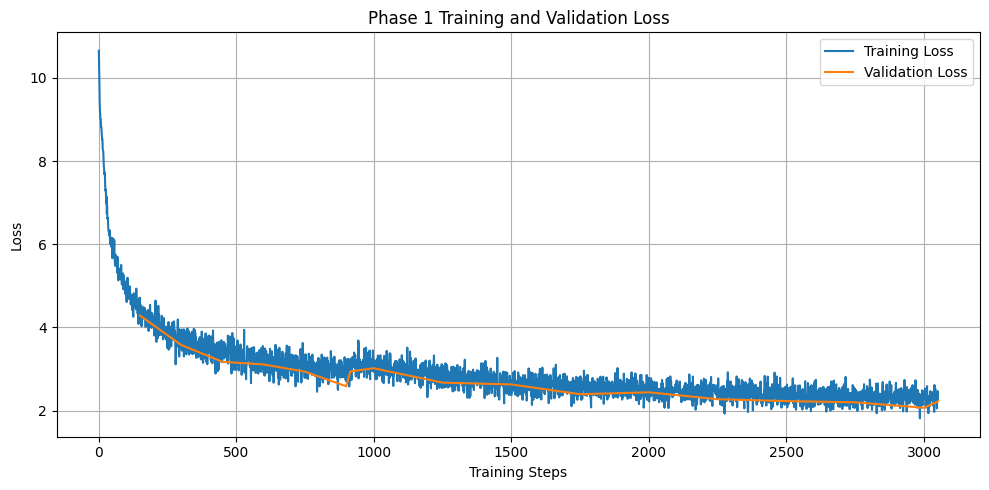

Loss plot saved to:
/kaggle/working/cs781_phase1/training_validation_loss.png


In [48]:
import matplotlib.pyplot as plt

# logs = trainer.state.log_history
logs = history

train_steps = []
train_loss = []
eval_steps = []
eval_loss = []

# for log in logs:
#     if ("loss" in log and "step" in log):
#         train_steps.append(log["step"])
#         train_loss.append(log["loss"])
#     if ("eval_loss" in log and "step" in log):
#         eval_steps.append(log["step"])
#         eval_loss.append(log["eval_loss"])

for step, loss, _ in logs['train']:
    train_steps.append(step)
    train_loss.append(loss)
for step, loss, _ in logs["val"]:
    eval_steps.append(step)
    eval_loss.append(loss)

plt.figure(figsize=(10, 5))
plt.plot(train_steps, train_loss, label="Training Loss")
plt.plot(eval_steps, eval_loss, label="Validation Loss")
plt.xlabel("Training Steps")
plt.ylabel("Loss")
plt.title("Phase 1 Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(LOSS_PLOT_PATH, dpi=200)
plt.show()

print("Loss plot saved to:")
print(LOSS_PLOT_PATH)

## 14. Save Final Model to Kaggle Output

In [43]:
# trainer.save_model(MODEL_OUTPUT_DIR)
# tokenizer.save_pretrained(MODEL_OUTPUT_DIR)

# print("Final model saved to:")
# print(MODEL_OUTPUT_DIR)

## 15. Push Model to Hugging Face Hub

In [44]:
# model.push_to_hub(HF_MODEL_REPO, token=HF_TOKEN)
# tokenizer.push_to_hub(HF_MODEL_REPO, token=HF_TOKEN)

# print("Model and tokenizer pushed successfully.")

## 16. Load Test Data from HuggingFace

In [51]:
from huggingface_hub import hf_hub_download

test_file_path = hf_hub_download(
    repo_id=HF_DATASET_REPO,
    filename=TEST_FILE,
    repo_type="dataset",
    token=HF_TOKEN
)

print("Test file:", test_file_path)

test.json: 0.00B [00:00, ?B/s]

Test file: /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Test/test.json


## 17. Load Test Prompts

In [52]:
with open(test_file_path, "r", encoding="utf-8") as f:
    test_data = json.load(f)

print("Number of test examples:", len(test_data))

Number of test examples: 1000


In [66]:
import json
import ijson
from tqdm import tqdm

saved_examples = []
example_id = 1

with open(test_file_path, "r", encoding="utf-8") as f:
    records = json.load(f)

    for data in tqdm(records.values()):
        # print(data['text'])
        if example_id > 4:
            break

        saved_examples.append({
            "id": example_id,
            "source": "test",
            "data": data['text']
        })

        example_id += 1

with open("test_examples_1_to_4.json", "w", encoding="utf-8") as f:
    json.dump(saved_examples, f, indent=2, ensure_ascii=False)


  0%|          | 4/1000 [00:00<00:00, 40427.03it/s]


## 18. Load Final Model for Generation

In [49]:

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

generation_model = model.to(device)
generation_model.eval()
# generation_model.config.use_cache = True

print("Device:", device)
print(f"Parameters: {sum(p.numel() for p in generation_model.parameters()) / 1e6:.2f}M")

Device: cuda
Parameters: 152.13M


## 19. Generate 128 Words
#### (words, not tokens)

In [57]:
# from collections import defaultdict

# MAX_GENERATION_TOKENS = 256   # prompt_len + this must be <= cfg.max_seq_len
# TEMPERATURE = 0.8             # 0 -> greedy
# MAX_PROMPT_TOKENS = None      # optional cap on prompt length (keeps the most recent tokens)

# def generate_batch(prompts, model, tokenizer, device, target_words=128):
#     model.eval()
#     max_len = model.cfg.max_seq_len - MAX_GENERATION_TOKENS
#     assert max_len > 1, "MAX_GENERATION_TOKENS too large for cfg.max_seq_len"
#     if MAX_PROMPT_TOKENS is not None:
#         max_len = min(max_len, MAX_PROMPT_TOKENS)
#     eos_id = tokenizer.stoi["</s>"]

#     # encode each prompt: keep <s>, drop the trailing </s>, left-truncate if too long
#     encoded = []
#     for p in prompts:
#         ids = tokenizer.encode(p)[:-1]
#         if len(ids) > max_len:
#             ids = ids[:1] + ids[-(max_len - 1):]
#         encoded.append(ids)

#     # group prompts of identical length -> batched generation without padding
#     by_len = defaultdict(list)
#     for idx, ids in enumerate(encoded):
#         by_len[len(ids)].append(idx)

#     predictions = [""] * len(prompts)
#     with torch.inference_mode():
#         for L, idxs in by_len.items():
#             input_ids = torch.tensor([encoded[i] for i in idxs], dtype=torch.long, device=device)
#             outputs = model.generate(
#                 input_ids,
#                 max_new_tokens=MAX_GENERATION_TOKENS,
#                 temperature=TEMPERATURE,
#                 top_k=None,
#                 eos_token_id=eos_id,
#             )
#             for row, i in enumerate(idxs):
#                 gen_ids = outputs[row, L:].tolist()
#                 if eos_id in gen_ids:                       # cut at first </s>
#                     gen_ids = gen_ids[:gen_ids.index(eos_id)]
#                 text = tokenizer.decode(gen_ids)
#                 predictions[i] = " ".join(text.split()[:target_words])

#     return predictions

## 20. Generate Predictions for the Test Set

In [101]:
# # ---- settings ----
# # MAX_GENERATION_TOKENS = 256   # ~128 words needs roughly 170-200 tokens
# # TEMPERATURE = 0.8             # 0 -> greedy
# TARGET_WORDS = 128
# BATCH_SIZE = 50
# PROMPT_TOKENS = None          # None -> auto (see below); or set e.g. 256 / 512

# generation_model = model_abl_3      # or the model loaded from your checkpoint
# generation_model.to(device).eval()

# eos_id = tokenizer.stoi["</s>"]
# max_prompt_len = generation_model.cfg.max_seq_len - MAX_GENERATION_TOKENS
# assert max_prompt_len > 1, "MAX_GENERATION_TOKENS too large for cfg.max_seq_len"

# items = list(test_data.items())
# total_examples = len(items)
# print(f"Total test examples: {total_examples}")

# # 1) encode every prompt (keep <s>, drop trailing </s>)
# encoded = [tokenizer.encode(record["text"])[:-1] for _, record in items]
# min_len, max_len = min(map(len, encoded)), max(map(len, encoded))
# print(f"prompt token lengths: min {min_len} | max {max_len} | allowed max {max_prompt_len}")

# # 2) one common prompt length for ALL prompts -> every batch is equal-length, no padding
# L = PROMPT_TOKENS if PROMPT_TOKENS is not None else min(min_len, max_prompt_len)
# L = min(L, min_len, max_prompt_len)
# encoded = [ids[:1] + ids[-(L - 1):] for ids in encoded]     # <s> + last (L-1) tokens
# print(f"all prompts cut to {L} tokens")

# # 3) generate directly in batches
# results = {}
# with torch.inference_mode():
#     for s in range(0, total_examples, BATCH_SIZE):
#         idxs = list(range(s, min(s + BATCH_SIZE, total_examples)))
#         input_ids = torch.tensor([encoded[i] for i in idxs], dtype=torch.long, device=device)

#         outputs = generation_model.generate(
#             input_ids,
#             max_new_tokens=MAX_GENERATION_TOKENS,
#             temperature=TEMPERATURE,
#             top_k=None,
#             eos_token_id=eos_id,
#         )

#         for row, i in enumerate(idxs):
#             gen_ids = outputs[row, L:].tolist()
#             if eos_id in gen_ids:                        # cut at first </s>
#                 gen_ids = gen_ids[:gen_ids.index(eos_id)]
#             words = tokenizer.decode(gen_ids).split()
#             results[i] = " ".join(words[:TARGET_WORDS])

#         done = idxs[-1] + 1
#         print(f"Completed {done}/{total_examples} ({100 * done / total_examples:.1f}%)")

# # 4) predictions in the original test_data order
# predictions = {str(example_id): {"text": results[i]} for i, (example_id, _) in enumerate(items)}

# # sanity checks
# assert len(predictions) == total_examples, "some prompts have no prediction"
# word_counts = [len(p["text"].split()) for p in predictions.values()]
# print(f"Done. {len(predictions)} predictions | avg words: {sum(word_counts)/len(word_counts):.1f} | "
#       f"under {TARGET_WORDS} words: {sum(c < TARGET_WORDS for c in word_counts)}")

In [104]:
# import inspect
# import torch
# import torch.nn.functional as F

# def masked_sdpa(q, k, v, attn_mask, dropout_p=0.0, training=False):
#     if attn_mask is None:
#         return causal_sdpa(q, k, v, dropout_p, training)            # training path unchanged
#     return F.scaled_dot_product_attention(q, k, v, attn_mask=attn_mask,
#                                           dropout_p=dropout_p if training else 0.0)

# def _gqa_forward(self, x, rope=None, positions=None, kv_cache=None, attn_mask=None):
#     B, T, _ = x.shape
#     q = self.q_proj(x).view(B, T, self.n_heads, self.hd).transpose(1, 2)
#     k = self.k_proj(x).view(B, T, self.n_kv, self.hd).transpose(1, 2)
#     v = self.v_proj(x).view(B, T, self.n_kv, self.hd).transpose(1, 2)
#     if rope is not None:
#         q, k = rope(q, k, positions)
#     if kv_cache is not None:
#         k = torch.cat([kv_cache[0], k], dim=2)
#         v = torch.cat([kv_cache[1], v], dim=2)
#     new_cache = (k, v)
#     rep = self.n_heads // self.n_kv
#     out = masked_sdpa(q, k.repeat_interleave(rep, dim=1), v.repeat_interleave(rep, dim=1),
#                       attn_mask, self.dropout, self.training)
#     out = out.transpose(1, 2).reshape(B, T, self.n_heads * self.hd)
#     return self.o_proj(out), new_cache

# def _mla_forward(self, x, rope=None, positions=None, kv_cache=None, attn_mask=None):
#     B, T, _ = x.shape
#     q = self.q_up(self.q_norm(self.q_down(x))) if self.q_proj is None else self.q_proj(x)
#     q = q.view(B, T, self.H, self.dn + self.dr).transpose(1, 2)
#     latent = self.kv_norm(self.kv_down(x)).unsqueeze(1)
#     k_rope = None
#     if self.dr > 0:
#         q_nope, q_rope = q.split([self.dn, self.dr], dim=-1)
#         k_rope = self.k_rope_proj(x).unsqueeze(1)
#         q_rope, k_rope = rope(q_rope, k_rope, positions)
#     else:
#         q_nope = q
#     if kv_cache is not None:
#         latent = torch.cat([kv_cache[0], latent], dim=2)
#         if k_rope is not None:
#             k_rope = torch.cat([kv_cache[1], k_rope], dim=2)
#     new_cache = (latent, k_rope)
#     Tk = latent.size(2)
#     kv = self.kv_up(latent.squeeze(1)).view(B, Tk, self.H, self.dn + self.dv).transpose(1, 2)
#     k_nope, v = kv.split([self.dn, self.dv], dim=-1)
#     if self.dr > 0:
#         q_full = torch.cat([q_nope, q_rope], dim=-1)
#         k_full = torch.cat([k_nope, k_rope.expand(-1, self.H, -1, -1)], dim=-1)
#     else:
#         q_full, k_full = q_nope, k_nope
#     out = masked_sdpa(q_full, k_full, v, attn_mask, self.dropout, self.training)
#     out = out.transpose(1, 2).reshape(B, T, self.H * self.dv)
#     return self.o_proj(out), new_cache

# def patch_model(m):
#     """Attach the masked forwards to the classes this model instance really uses."""
#     for blk in m.blocks:
#         cls = type(blk.attn)
#         if "MLA" in cls.__name__:
#             cls.forward = _mla_forward
#         elif "GQA" in cls.__name__:
#             cls.forward = _gqa_forward
#         else:
#             raise TypeError(f"unknown attention class {cls.__name__}")
#     print("attention forward:", inspect.signature(type(m.blocks[0].attn).forward))

# patch_model(generation_model)      # use the same variable name your Cell 20 uses

attention forward: (self, x, rope=None, positions=None, kv_cache=None, attn_mask=None)


In [53]:
import os, json, zipfile, torch

# ---------------- settings ----------------
GEN = dict(temperature=0.6, top_k=50, top_p=0.9, repetition_penalty=1.1, no_repeat_ngram=6)
PROMPT_CAP = None        # None = pass the FULL prompt; e.g. 600 keeps only the last 600 tokens
MAX_NEW = 400            # max new tokens per prompt (generation stops earlier once >128 words exist)
TARGET_WORDS = 128
BATCH_SIZE = 32          # lower if you hit out-of-memory (long prompts)
TRAIN_BLOCK = 1024       # window the model was trained on (only used for the warning below)
ASCII_ONLY = True        # False allows Hindi / non-ASCII in the generated text
RUN_CHECK = True         # quick masked-vs-causal and padded-vs-unpadded check before generating

assert "generation_model" in globals(), "load the generation_model first (build DecoderLM and load_checkpoint)"
generation_model.to(DEVICE).eval()

def _amp():
    if not str(DEVICE).startswith("cuda"):
        return "cpu", None
    return "cuda", (torch.bfloat16 if torch.cuda.get_device_capability(0)[0] >= 8 else torch.float16)

# ---------------- tokens that must never be generated ----------------
PAD = tokenizer.stoi["<pad>"]
SPECIAL = [tokenizer.stoi[t] for t in ("<pad>", "<unk>", "<s>", "</s>")]
WS_IDS = [i for i, t in enumerate(tokenizer.itos) if isinstance(t, bytes) and t.strip() == b""]
BAD_IDS = [i for i, t in enumerate(tokenizer.itos) if isinstance(t, bytes) and any(b >= 128 for b in t)]
BAN = SPECIAL + WS_IDS + (BAD_IDS if ASCII_ONLY else [])

# ---------------- batched generation with left padding + attention mask ----------------
@torch.no_grad()
def generate_texts(model, id_rows, gen_kwargs, batch_size=32, target_words=128, max_new=400, verbose=True):
    """id_rows: list of token-id lists of ANY length; each batch is left-padded and masked."""
    model.eval()
    dev_type, amp_dtype = _amp()
    order = sorted(range(len(id_rows)), key=lambda i: -len(id_rows[i]))     # longest first: OOM shows up early
    out, finished = [""] * len(id_rows), 0
    for s in range(0, len(order), batch_size):
        idxs = order[s:s + batch_size]
        L = max(len(id_rows[i]) for i in idxs)
        x = torch.full((len(idxs), L), PAD, dtype=torch.long)
        m = torch.zeros((len(idxs), L), dtype=torch.long)
        for r, i in enumerate(idxs):
            ids = id_rows[i]
            x[r, L - len(ids):] = torch.tensor(ids, dtype=torch.long)
            m[r, L - len(ids):] = 1
        x, m = x.to(DEVICE), m.to(DEVICE)
        with torch.autocast(device_type=dev_type, dtype=amp_dtype, enabled=amp_dtype is not None):
            full = model.generate(x, attention_mask=m, max_new_tokens=max_new, ban_ids=BAN, pad_id=PAD,
                                  tokenizer=tokenizer, target_words=target_words, **gen_kwargs)
        for r, i in enumerate(idxs):
            out[i] = " ".join(tokenizer.decode(full[r, L:].tolist()).split()[:target_words])
        finished += len(idxs)
        if verbose:
            print(f"generated {finished}/{len(id_rows)}")
    return out

def generate_texts_retry(model, id_rows, gen_kwargs, min_words=128, retries=3, temp_step=0.1, **kw):
    """Re-generates rows that came out under min_words, with a slightly higher temperature each retry."""
    texts = generate_texts(model, id_rows, gen_kwargs, **kw)
    for r in range(1, retries + 1):
        short = [i for i, t in enumerate(texts) if len(t.split()) < min_words]
        if not short:
            break
        kw2 = dict(gen_kwargs)
        kw2["temperature"] = max(kw2.get("temperature", 0.5), 0.3) + temp_step * r
        print(f"retry {r}: {len(short)} short outputs, T={kw2['temperature']:.2f}")
        new = generate_texts(model, [id_rows[i] for i in short], kw2, verbose=False, **kw)
        for i, t in zip(short, new):
            if len(t.split()) > len(texts[i].split()):
                texts[i] = t
    return texts

# ---------------- build prompts: full text, no truncation ----------------
items = list(test_data.items())
rows = []
for _, rec in items:
    cleaned = clean_court_text(rec["text"])
    assert cleaned is not None, "test record without text"
    ids = tokenizer.encode(cleaned)[1:-1]                     # drop <s> and </s>
    rows.append(ids[-PROMPT_CAP:] if PROMPT_CAP else ids)
lens = [len(r) for r in rows]
print(f"prompts: {len(rows)} | tokens min {min(lens)} / mean {sum(lens)/len(lens):.0f} / max {max(lens)}")
print(f"{sum(l + MAX_NEW > TRAIN_BLOCK for l in lens)}/{len(lens)} prompts will generate past the "
      f"{TRAIN_BLOCK}-token training window")
assert max(lens) + MAX_NEW <= generation_model.cfg.max_seq_len, "longest prompt + MAX_NEW exceeds max_seq_len"

# ---------------- quick correctness check of the masked path ----------------
if RUN_CHECK:
    with torch.no_grad():
        ids = torch.tensor([rows[0][-300:]], dtype=torch.long, device=DEVICE)
        l_causal, _, _ = generation_model(ids)                                              # no mask -> training path
        l_mask, _, _ = generation_model(ids, attention_mask=torch.ones_like(ids))           # explicit-mask path
        pad_n = 37
        b = torch.cat([torch.full((1, pad_n), PAD, dtype=torch.long, device=DEVICE), ids], dim=1)
        m = torch.cat([torch.zeros(1, pad_n), torch.ones(1, ids.size(1))], dim=1).to(DEVICE)
        l_pad, _, _ = generation_model(b, attention_mask=m, last_only=True)                 # left-padded + masked
    d1 = (l_causal - l_mask).abs().max().item()
    d2 = (l_causal[:, -1:] - l_pad).abs().max().item()
    print(f"check: causal vs mask {d1:.2e} | padded vs unpadded {d2:.2e}")
    if max(d1, d2) > 1e-2:
        print("WARNING: masked path differs from the causal path; do not trust the predictions, check the patched blocks")

# ---------------- generate + save ----------------
texts = generate_texts_retry(generation_model, rows, GEN, batch_size=BATCH_SIZE, max_new=MAX_NEW, target_words=TARGET_WORDS)
predictions = {str(eid): {"text": t} for (eid, _), t in zip(items, texts)}

wc = [len(p["text"].split()) for p in predictions.values()]
assert len(predictions) == len(items), "some prompts have no prediction"
print(f"{len(predictions)} predictions | avg words {sum(wc)/len(wc):.1f} | under {TARGET_WORDS} words: {sum(c < TARGET_WORDS for c in wc)}")

# os.makedirs(OUTPUT_DIR, exist_ok=True)
# with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
#     json.dump(predictions, f, ensure_ascii=False, indent=2)
# with zipfile.ZipFile(SUBMISSION_ZIP, "w", zipfile.ZIP_DEFLATED) as z:
#     z.write(PREDICTION_PATH, arcname="prediction.json")
# print("saved:", PREDICTION_PATH, "and", SUBMISSION_ZIP)

prompts: 1000 | tokens min 541 / mean 613 / max 952
301/1000 prompts will generate past the 1024-token training window
check: causal vs mask 0.00e+00 | padded vs unpadded 1.05e-05
generated 32/1000
generated 64/1000
generated 96/1000
generated 128/1000
generated 160/1000
generated 192/1000
generated 224/1000
generated 256/1000
generated 288/1000
generated 320/1000
generated 352/1000
generated 384/1000
generated 416/1000
generated 448/1000
generated 480/1000
generated 512/1000
generated 544/1000
generated 576/1000
generated 608/1000
generated 640/1000
generated 672/1000
generated 704/1000
generated 736/1000
generated 768/1000
generated 800/1000
generated 832/1000
generated 864/1000
generated 896/1000
generated 928/1000
generated 960/1000
generated 992/1000
generated 1000/1000
retry 1: 1 short outputs, T=0.70
1000 predictions | avg words 128.0 | under 128 words: 0


In [126]:
# with torch.no_grad():
#     a = torch.tensor([val_tokens[0][:300]], device=DEVICE)
#     la, _, _ = generation_model(a, last_only=True)                                   # unpadded, fp32
#     pad_n = 37
#     b = torch.cat([torch.zeros(1, pad_n, dtype=torch.long, device=DEVICE), a], dim=1)
#     m = torch.cat([torch.zeros(1, pad_n), torch.ones(1, a.size(1))], dim=1).to(DEVICE)
#     lb, _, _ = generation_model(b, attention_mask=m, last_only=True)                 # left-padded + masked
# print("max |logit diff| padded vs unpadded:", (la - lb).abs().max().item())

## 21. Save prediction.json

In [56]:
with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
    json.dump(
        predictions,
        f,
        ensure_ascii=False,
        indent=2
    )

print("prediction.json saved:")
print(PREDICTION_PATH)

prediction.json saved:
/kaggle/working/cs781_phase1/prediction.json


## 22. Create CodaBench Submission ZIP

In [57]:
with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as zipf:
    zipf.write(PREDICTION_PATH, arcname="prediction.json")

print("Codabench submission created:")
print(SUBMISSION_ZIP)

Codabench submission created:
/kaggle/working/cs781_phase1/submission.zip


In [1]:
!zip -r best_models.zip checkpoints -i "*_best.pt"

  adding: checkpoints/mla-rope-moe_best.pt (deflated 7%)
  adding: checkpoints/gqa-sinusoidal-moe_best.pt (deflated 7%)
  adding: checkpoints/abl_mla_rope_moe_best.pt (deflated 7%)
  adding: checkpoints/mla-sinusoidal-moe_best.pt (deflated 7%)
  adding: checkpoints/gqa-rope-moe_best.pt (deflated 7%)
  adding: checkpoints/abl_gqa_sin_moe_best.pt (deflated 7%)
  adding: checkpoints/abl_gqa_rope_moe_best.pt (deflated 7%)
  adding: checkpoints/abl_mla_sin_moe_best.pt (deflated 7%)
